# HuggingFace Transformers: API, Models and Fine-Tuning Techniques - Day 4

In [3]:
import sys
import torch
import transformers
import PIL

print("Python version:", sys.version)
print("Torch version:", torch.__version__)
print("Transformers version:", transformers.__version__)
print("PIL version:", PIL.__version__)

Python version: 3.14.8 (main, Sep 30 2026, 17:55:09) [Clang 21.0.0 (clang-2100.3.34.2)]
Torch version: 2.14.1
Transformers version: 5.19.0
PIL version: 12.3.0


#### Necessary modules for today's sessions
 - PEFT 
 - BitsAndBytes
 - TrackIO

In [4]:
!pip install peft

In [5]:
!pip install bitsandbytes

In [6]:
!pip install trackio

In [15]:
(244*224) / 768

71.16666666666667

In [7]:
from transformers import AutoModel

model = AutoModel.from_pretrained("google/vit-base-patch16-224-in21k")
model

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

ViTModel(
  (embeddings): ViTEmbeddings(
    (patch_embeddings): ViTPatchEmbeddings(
      (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
    )
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (layers): ModuleList(
    (0-11): 12 x ViTLayer(
      (attention): ViTAttention(
        (q_proj): Linear(in_features=768, out_features=768, bias=True)
        (k_proj): Linear(in_features=768, out_features=768, bias=True)
        (v_proj): Linear(in_features=768, out_features=768, bias=True)
        (o_proj): Linear(in_features=768, out_features=768, bias=True)
      )
      (layernorm_before): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (layernorm_after): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (mlp): ViTMLP(
        (activation_fn): GELUActivation()
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
      )
      (dropout): Dro

In [10]:
for name, layer in model.named_parameters():
    print(f"{name}")


embeddings.cls_token
embeddings.position_embeddings
embeddings.patch_embeddings.projection.weight
embeddings.patch_embeddings.projection.bias
layers.0.attention.q_proj.weight
layers.0.attention.q_proj.bias
layers.0.attention.k_proj.weight
layers.0.attention.k_proj.bias
layers.0.attention.v_proj.weight
layers.0.attention.v_proj.bias
layers.0.attention.o_proj.weight
layers.0.attention.o_proj.bias
layers.0.layernorm_before.weight
layers.0.layernorm_before.bias
layers.0.layernorm_after.weight
layers.0.layernorm_after.bias
layers.0.mlp.fc1.weight
layers.0.mlp.fc1.bias
layers.0.mlp.fc2.weight
layers.0.mlp.fc2.bias
layers.1.attention.q_proj.weight
layers.1.attention.q_proj.bias
layers.1.attention.k_proj.weight
layers.1.attention.k_proj.bias
layers.1.attention.v_proj.weight
layers.1.attention.v_proj.bias
layers.1.attention.o_proj.weight
layers.1.attention.o_proj.bias
layers.1.layernorm_before.weight
layers.1.layernorm_before.bias
layers.1.layernorm_after.weight
layers.1.layernorm_after.bias
la

In [11]:
from peft import get_peft_model, LoraConfig

LoraConfig?

Init signature:
LoraConfig(
    task_type: 'Optional[Union[str, TaskType]]' = None,
    peft_type: 'Optional[Union[str, PeftType]]' = None,
    auto_mapping: 'Optional[dict]' = None,
    peft_version: 'Optional[str]' = None,
    base_model_name_or_path: 'Optional[str]' = None,
    revision: 'Optional[str]' = None,
    inference_mode: 'bool' = False,
    r: 'int' = 8,
    target_modules: 'Optional[Union[list[str], str]]' = None,
    exclude_modules: 'Optional[Union[list[str], str]]' = None,
    lora_alpha: 'int' = 8,
    lora_dropout: 'float' = 0.0,
    fan_in_fan_out: 'bool' = False,
    bias: "Literal['none', 'all', 'lora_only']" = 'none',
    use_rslora: 'bool' = False,
    modules_to_save: 'Optional[list[str]]' = None,
    init_lora_weights: "bool | Literal['gaussian', 'eva', 'olora', 'pissa', 'pissa_niter_[number of iters]', 'corda', 'loftq', 'orthogonal', 'mica']" = True,
    layers_to_transform: 'Optional[Union[list[int], int]]' = None,
    layers_pattern: 'Optional[Union[list[st

---

### LLM Fine-tuning: Optimization and Techniques

#### PEFT - Parameter-Efficient-Fine-Tuning

PEFT offers parameter-efficient methods for finetuning large pretrained models. 

The traditional paradigm is to finetune all of a model’s parameters for each downstream task, but this is becoming exceedingly costly and impractical because of the enormous number of parameters in models today.

PEFT involves the following strategies for making fine-tuning efficient:
  - **Adapter Tuning**: https://arxiv.org/pdf/1902.00751.pdf
  - **LoRA (Low-Rank Adaptation)**: https://arxiv.org/pdf/2106.09685.pdf
  - **Orthogonal Fine-Tuning**:
  - **Prompt Tuning Techniques**:
     * **Prompt Tuning**: https://arxiv.org/pdf/2104.08691.pdf
     * **Prefix Tuning (P-Tuning)**: https://arxiv.org/pdf/2103.10385.pdf
     * **P-Tuning v2**: https://arxiv.org/pdf/2110.07602.pdf
---

##### LoRA
Instead, it is more efficient to train a smaller number of prompt parameters or use a reparametrization method like low-rank adaptation (LoRA) to reduce the number of trainable parameters.

---

##### Prompt Tuning
Based on the whitepaper titled ["The Power of Scale for Parameter-Efficient Prompt Tuning"]( https://arxiv.org/pdf/2104.08691.pdf) introduces **Prompt Tuning**, a technique that optimizes continuous "soft prompts" while keeping the underlying language model completely frozen. 

Core Mechanics
 - **Soft Prompts**: Instead of using manual text descriptions, it introduces \(k\) tunable virtual tokens prepended to the input text embedding.
 - **Frozen Weights**: The base language model's weights remain entirely fixed during downstream adaptation.
 - **Backpropagation**: Only the dedicated prompt parameters are updated via gradient descent.
 - **Text-to-Text Format**: It treats all downstream applications as text generation tasks.

Performance improves drastically as model size scales up. When applied to a model with 11 billion parameters (T5-xxl), it matches full model fine-tuning performance.

---
##### Prefix Tuning (P-Tuning)
Based on the whitepaper ["GPT Understands, Too"](https://arxiv.org/pdf/2103.10385.pdf) introduces P-Tuning, a parameter-efficient method that replaces manual, discrete text prompts with trainable continuous prompt embeddings to enhance Natural Language Understanding (NLU) tasks. By optimizing small virtual tokens via a prompt encoder while keeping the underlying language model frozen, this technique stabilizes performance and enables GPT models to match or exceed BERT models.

---
##### P-Tuning v2

["P-Tuning v2: Prompt Tuning Can Be Comparable to Fine-tuning Universally Across Scales and Tasks"](https://arxiv.org/pdf/2110.07602) introduces an advanced parameter-efficient method that allows prompt tuning to match full fine-tuning universally. It extends standard prompt tuning across models of all sizes (from 330M parameters up to 10B+) and handles complex tasks like sequence labeling.


---

**Training using PEFT**

Each PEFT method is defined by a `PeftConfig` class that stores all the important parameters for building a `PeftModel`. For example, to train with `LoRA`, load and create a `LoraConfig` class and specify the following parameters:

 - **task_type:** the task to train for - defined within `TaskType` Enum class:
    - SEQ_CLS: Text classification.
    - SEQ_2_SEQ_LM: Sequence-to-sequence language modeling.
    - CAUSAL_LM: Causal language modeling.
    - TOKEN_CLS: Token classification.
    - QUESTION_ANS: Question answering.
    - FEATURE_EXTRACTION: Feature extraction. Provides the hidden states which can be use as embeddings or features for downstream tasks.

 - **inference_mode:** whether you’re using the model for inference or not
 - **r:** the dimension of the low-rank matrices
 - **lora_alpha:** the scaling factor for the low-rank matrices
 - **lora_dropout:** the dropout probability of the LoRA layers

#### LoRA - Low-Rank Adaptation

LoRA is a parameter-efficient fine-tuning (PEFT) method that freezes the weights of a large pre-trained model and adds small, trainable "low-rank" matrices to adapt it to a new task.

Instead of updating the entire large weight matrix during fine-tuning, LoRA decomposes the update into two smaller matrices, drastically reducing the number of trainable parameters, memory requirements, and training time.

**Benefits:**
  - **Efficiency:** Greatly lowers the computational and memory costs compared to full fine-tuning.
  - **Speed:** Speeds up the fine-tuning process.
  - **Storage:** Creates much smaller model checkpoints.
  - **Flexibility:** Allows for quick switching between different fine-tuned versions of a model without reloading the entire base model.
  - **Applications:** Customizing large language models for specific tasks, as well as adapting image generation and voice recognition models. 

LoRA is one of the most popular PEFT methods and a good starting point if you’re just getting started with PEFT. It was originally developed for LLMs but it is a tremendously popular training method for diffusion models because of its efficiency and effectiveness.

More on LoRA whitepaper: https://arxiv.org/pdf/2106.09685

LoRA represents the weight updates ∆W with two smaller matrices (called update matrices) through low-rank decomposition. 

These new matrices can be trained to adapt to the new data while keeping the overall number of parameters low. 

The original weight matrix remains frozen and doesn’t receive any further updates. To produce the final results, the original and extra adapted weights are combined. 

You could also merge the adapter weights with the base model to eliminate inference latency.

![LoRA Animated Diagram](./lora_animated.gif "LoRA Animated Illustration from Huggingface")

In principle, LoRA can be applied to any subset of weight matrices in a neural network to reduce the number of trainable parameters. 

However, for simplicity and further parameter efficiency, LoRA is typically only applied to the attention blocks in Transformer models. 

The resulting number of trainable parameters in a LoRA model depends on the size of the update matrices, which is determined mainly by the rank *r* and the shape of the original *weight* matrix.

#### Other Techniques and variations of LoRA

##### Mixture of LoRA Experts (X-LoRA)

`X-LoRA` is a mixture of experts (MoE) method for LoRA which works by using dense or sparse gating to dynamically activate LoRA experts. 

The LoRA experts as well as the base model are frozen during training, resulting in a low parameter count as only the gating layers must be trained. 

In particular, the gating layers output scalings which (depending on config) are granular on the layer and token level. Additionally, during inference, X-LoRA dynamically activates LoRA adapters to recall knowledge and effectively mix them.

For each step, X-LoRA requires the base model to be run twice: first, to get hidden states without any LoRA adapters, and secondly, the hidden states are used to calculate scalings which are applied to the LoRA adapters and the model is run a second time. The output of the second run is the result of the model step.

Ultimately, X-LoRA allows the model to reflect upon its knowledge because of the dual forward pass scheme, and dynamically reconfigure the architecture.

![X-Lora Example Illustration](./token_by_token_scalings.gif)


##### Low-Rank Hadamard Product (LoHa)
Low-rank decomposition can impact performance because the weight updates are limited to the low-rank space, which can constrain a model’s expressiveness. 

However, you don’t necessarily want to use a larger rank because it increases the number of trainable parameters. 

To address this, LoHa (a method originally developed for computer vision) was applied to diffusion models where the ability to generate diverse images is an important consideration.

LoHa should also work with general model types, but the embedding layers aren’t currently implemented in PEFT.

LoHa uses the Hadamard product (element-wise product) instead of the matrix product. ∆W is represented by four smaller matrices instead of two - like in LoRA - and each pair of these low-rank matrices are combined with the Hadamard product. 

As a result, ∆W can have the same number of trainable parameters but a higher rank and expressivity. The research paper is available at: https://arxiv.org/pdf/2501.02969


##### Low-Rank Kronecker Product (LoKr)

LoKr is very similar to LoRA and LoHa, and it is also mainly applied to diffusion models, though you could also use it with other model types. 

LoKr replaces the matrix product with the Kronecker product instead. The Kronecker product decomposition creates a block matrix which preserves the rank of the original weight matrix. 

Another benefit of the Kronecker product is that it can be vectorized by stacking the matrix columns. This can speed up the process because you’re avoiding fully reconstructing ∆W.
The research paper is available at: https://arxiv.org/pdf/2505.15334


![](./lora_loha_lokr.png)

---

#### Orthogonal Finetuning (OFT)

OFT is a method that primarily focuses on preserving a pretrained model’s generative performance in the finetuned model. 

It tries to maintain the same cosine similarity (hyperspherical energy) between all pairwise neurons in a layer because this better captures the semantic information among neurons. 

This means OFT is more capable at preserving the subject and it is better for controllable generation (similar to ControlNet).

OFT preserves the hyperspherical energy by learning an orthogonal transformation for neurons to keep the cosine similarity between them unchanged. 

In practice, this means taking the matrix product of an orthogonal matrix with the pretrained weight matrix. However, to be parameter-efficient, the orthogonal matrix is represented as a block-diagonal matrix with rank *r* blocks. Whereas LoRA reduces the number of trainable parameters with low-rank structures, OFT reduces the number of trainable parameters with a sparse block-diagonal matrix structure.

Research Paper: https://arxiv.org/pdf/2506.19847

![](./oft.png)





##### Orthogonal Butterfly (BOFT)
BOFT is an improved orthogonal finetuning method that focuses on preserving a pretrained model’s generative capabilities while being significantly more parameter-efficient than standard OFT. 

Like OFT, BOFT maintains the same cosine similarity (hyperspherical energy) between all pairwise neurons in a layer by applying an orthogonal transformation to the pretrained weight matrix, ensuring the semantic relationships among neurons are preserved.

Instead of using a block-diagonal orthogonal matrix, BOFT factorizes the orthogonal transformation into a product of sparse butterfly matrices (originally introduced in the Cooley–Tukey FFT). 

Unlike OFT’s block-diagonal rotations, which only mix inputs within each block, the butterfly structure guarantees that every input can influence every output, producing a dense connectivity with just O(d log d) parameters. This factorization preserves expressivity while drastically reducing the parameter count compared to OFT (at the expense of computation time).

In practice, BOFT multiplies each pretrained weight matrix by a sequence of butterfly-structured orthogonal factors, enabling efficient and expressive neuron rotations. This makes BOFT well-suited for controllable generation and tasks where maintaining the pretrained model’s subject representation is critical, while also scaling to larger models with lower memory and compute overhead.

Research Paper: https://arxiv.org/pdf/2311.06243

![](./BOFT_comparison.png)

#### Exploring various PEFT Techniques in HuggingFace
https://huggingface.co/docs/peft/index


In [16]:
pW = 5.6
uW = 4.6
d = pW - uW
d

1.0

#### Using PEFT method for Fine-Tuning

In [12]:
import peft
peft.__version__

'0.21.2'

In [13]:
from peft import TaskType
print(TaskType)
print(dir(TaskType))

<enum 'TaskType'>
['CAUSAL_LM', 'FEATURE_EXTRACTION', 'QUESTION_ANS', 'SEQ_2_SEQ_LM', 'SEQ_CLS', 'TOKEN_CLS', '__add__', '__class__', '__contains__', '__delattr__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getitem__', '__getnewargs__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__iter__', '__le__', '__len__', '__lt__', '__members__', '__mod__', '__module__', '__mul__', '__name__', '__ne__', '__new__', '__qualname__', '__reduce__', '__reduce_ex__', '__repr__', '__rmod__', '__rmul__', '__setattr__', '__sizeof__', '__str__', '__subclasshook__', 'capitalize', 'casefold', 'center', 'count', 'encode', 'endswith', 'expandtabs', 'find', 'format', 'format_map', 'index', 'isalnum', 'isalpha', 'isascii', 'isdecimal', 'isdigit', 'isidentifier', 'islower', 'isnumeric', 'isprintable', 'isspace', 'istitle', 'isupper', 'join', 'ljust', 'lower', 'lstrip', 'maketrans', 'partition', 'removeprefix', 'removesuffix', 'replace', 'rfind', 'rin

In [14]:
from peft import TaskType
for task_type in TaskType.__members__:
    print(task_type)

SEQ_CLS
SEQ_2_SEQ_LM
CAUSAL_LM
TOKEN_CLS
QUESTION_ANS
FEATURE_EXTRACTION


In [15]:
# PEFT for Vision Transformer (ViT) Example
from transformers import AutoImageProcessor, AutoModelForImageClassification
from peft import LoraConfig, TaskType, get_peft_model

In [16]:
from transformers import AutoModelForImageClassification

checkpoint = "google/vit-base-patch16-224-in21k"

model = AutoModelForImageClassification.from_pretrained(checkpoint)
for name, param in model.named_parameters():
    print(name)


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.weight   | MISSING    | 
classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


vit.embeddings.cls_token
vit.embeddings.position_embeddings
vit.embeddings.patch_embeddings.projection.weight
vit.embeddings.patch_embeddings.projection.bias
vit.layers.0.attention.q_proj.weight
vit.layers.0.attention.q_proj.bias
vit.layers.0.attention.k_proj.weight
vit.layers.0.attention.k_proj.bias
vit.layers.0.attention.v_proj.weight
vit.layers.0.attention.v_proj.bias
vit.layers.0.attention.o_proj.weight
vit.layers.0.attention.o_proj.bias
vit.layers.0.layernorm_before.weight
vit.layers.0.layernorm_before.bias
vit.layers.0.layernorm_after.weight
vit.layers.0.layernorm_after.bias
vit.layers.0.mlp.fc1.weight
vit.layers.0.mlp.fc1.bias
vit.layers.0.mlp.fc2.weight
vit.layers.0.mlp.fc2.bias
vit.layers.1.attention.q_proj.weight
vit.layers.1.attention.q_proj.bias
vit.layers.1.attention.k_proj.weight
vit.layers.1.attention.k_proj.bias
vit.layers.1.attention.v_proj.weight
vit.layers.1.attention.v_proj.bias
vit.layers.1.attention.o_proj.weight
vit.layers.1.attention.o_proj.bias
vit.layers.1.lay

In [17]:
print(f"{model.num_parameters(only_trainable=True):,} trainable parameters")

85,800,194 trainable parameters


In [26]:
TaskType.__members__

mappingproxy({'SEQ_CLS': <TaskType.SEQ_CLS: 'SEQ_CLS'>,
              'SEQ_2_SEQ_LM': <TaskType.SEQ_2_SEQ_LM: 'SEQ_2_SEQ_LM'>,
              'CAUSAL_LM': <TaskType.CAUSAL_LM: 'CAUSAL_LM'>,
              'TOKEN_CLS': <TaskType.TOKEN_CLS: 'TOKEN_CLS'>,
              'QUESTION_ANS': <TaskType.QUESTION_ANS: 'QUESTION_ANS'>,
              'FEATURE_EXTRACTION': <TaskType.FEATURE_EXTRACTION: 'FEATURE_EXTRACTION'>})

In [5]:
from peft import LoraConfig, get_peft_model, TaskType
from transformers import AutoModelForImageClassification

checkpoint = "google/vit-base-patch16-224-in21k"

model = AutoModelForImageClassification.from_pretrained(checkpoint)

print(f"{model.num_parameters(only_trainable=True):,} trainable parameters")

lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,  # For image classification
    inference_mode=False,
    r=8,
    lora_alpha=16,
    lora_dropout=0.1,
    #target_modules="all-linear",
    target_modules=[
        "q_proj", 
        "k_proj", 
        "v_proj"
    ],  # Attention
    modules_to_save=["classifier"]  # Save the classifier layer for fine-tuning
)
model

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.weight | UNEXPECTED | 
pooler.dense.bias   | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


85,800,194 trainable parameters


ViTForImageClassification(
  (vit): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (layers): ModuleList(
      (0-11): 12 x ViTLayer(
        (attention): ViTAttention(
          (q_proj): Linear(in_features=768, out_features=768, bias=True)
          (k_proj): Linear(in_features=768, out_features=768, bias=True)
          (v_proj): Linear(in_features=768, out_features=768, bias=True)
          (o_proj): Linear(in_features=768, out_features=768, bias=True)
        )
        (layernorm_before): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (layernorm_after): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (mlp): ViTMLP(
          (activation_fn): GELUActivation()
          (fc1): Linear(in_features=768, out_features=3072, bias=True)
          (fc2): Linear

In [6]:
peft_model = get_peft_model(model, lora_config)

peft_model

PeftModelForSequenceClassification(
  (base_model): LoraModel(
    (model): ViTForImageClassification(
      (vit): ViTModel(
        (embeddings): ViTEmbeddings(
          (patch_embeddings): ViTPatchEmbeddings(
            (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
          )
          (dropout): Dropout(p=0.0, inplace=False)
        )
        (layers): ModuleList(
          (0-11): 12 x ViTLayer(
            (attention): ViTAttention(
              (q_proj): lora.Linear(
                (base_layer): Linear(in_features=768, out_features=768, bias=True)
                (lora_dropout): ModuleDict(
                  (default): Dropout(p=0.1, inplace=False)
                )
                (lora_A): ModuleDict(
                  (default): Linear(in_features=768, out_features=8, bias=False)
                )
                (lora_B): ModuleDict(
                  (default): Linear(in_features=8, out_features=768, bias=False)
                )
                (

In [7]:
model

ViTForImageClassification(
  (vit): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (layers): ModuleList(
      (0-11): 12 x ViTLayer(
        (attention): ViTAttention(
          (q_proj): lora.Linear(
            (base_layer): Linear(in_features=768, out_features=768, bias=True)
            (lora_dropout): ModuleDict(
              (default): Dropout(p=0.1, inplace=False)
            )
            (lora_A): ModuleDict(
              (default): Linear(in_features=768, out_features=8, bias=False)
            )
            (lora_B): ModuleDict(
              (default): Linear(in_features=8, out_features=768, bias=False)
            )
            (lora_embedding_A): ParameterDict()
            (lora_embedding_B): ParameterDict()
            (lora_magnitude_vector): ModuleDict()
          )
          (k_proj):

In [20]:
model

ViTForImageClassification(
  (vit): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (layers): ModuleList(
      (0-10): 11 x ViTLayer(
        (attention): ViTAttention(
          (q_proj): Linear(in_features=768, out_features=768, bias=True)
          (k_proj): Linear(in_features=768, out_features=768, bias=True)
          (v_proj): Linear(in_features=768, out_features=768, bias=True)
          (o_proj): Linear(in_features=768, out_features=768, bias=True)
        )
        (layernorm_before): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (layernorm_after): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (mlp): ViTMLP(
          (activation_fn): GELUActivation()
          (fc1): Linear(in_features=768, out_features=3072, bias=True)
          (fc2): Linear

In [27]:
peft_model

PeftModelForSequenceClassification(
  (base_model): LoraModel(
    (model): ViTForImageClassification(
      (vit): ViTModel(
        (embeddings): ViTEmbeddings(
          (patch_embeddings): ViTPatchEmbeddings(
            (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
          )
          (dropout): Dropout(p=0.0, inplace=False)
        )
        (layers): ModuleList(
          (0-11): 12 x ViTLayer(
            (attention): ViTAttention(
              (q_proj): lora.Linear(
                (base_layer): Linear(in_features=768, out_features=768, bias=True)
                (lora_dropout): ModuleDict(
                  (default): Dropout(p=0.1, inplace=False)
                )
                (lora_A): ModuleDict(
                  (default): Linear(in_features=768, out_features=8, bias=False)
                )
                (lora_B): ModuleDict(
                  (default): Linear(in_features=8, out_features=768, bias=False)
                )
                (

In [24]:
for name, param in peft_model.named_parameters():
    print(name)


base_model.model.vit.embeddings.cls_token
base_model.model.vit.embeddings.position_embeddings
base_model.model.vit.embeddings.patch_embeddings.projection.weight
base_model.model.vit.embeddings.patch_embeddings.projection.bias
base_model.model.vit.layers.0.attention.q_proj.base_layer.weight
base_model.model.vit.layers.0.attention.q_proj.base_layer.bias
base_model.model.vit.layers.0.attention.q_proj.lora_A.default.weight
base_model.model.vit.layers.0.attention.q_proj.lora_B.default.weight
base_model.model.vit.layers.0.attention.k_proj.base_layer.weight
base_model.model.vit.layers.0.attention.k_proj.base_layer.bias
base_model.model.vit.layers.0.attention.k_proj.lora_A.default.weight
base_model.model.vit.layers.0.attention.k_proj.lora_B.default.weight
base_model.model.vit.layers.0.attention.v_proj.base_layer.weight
base_model.model.vit.layers.0.attention.v_proj.base_layer.bias
base_model.model.vit.layers.0.attention.v_proj.lora_A.default.weight
base_model.model.vit.layers.0.attention.v_pro

In [27]:
model

ViTForImageClassification(
  (vit): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (layers): ModuleList(
      (0-11): 12 x ViTLayer(
        (attention): ViTAttention(
          (q_proj): lora.Linear(
            (base_layer): Linear(in_features=768, out_features=768, bias=True)
            (lora_dropout): ModuleDict(
              (default): Dropout(p=0.1, inplace=False)
            )
            (lora_A): ModuleDict(
              (default): Linear(in_features=768, out_features=8, bias=False)
            )
            (lora_B): ModuleDict(
              (default): Linear(in_features=8, out_features=768, bias=False)
            )
            (lora_embedding_A): ParameterDict()
            (lora_embedding_B): ParameterDict()
            (lora_magnitude_vector): ModuleDict()
          )
          (k_proj):

In [29]:
peft_model.print_trainable_parameters()

trainable params: 26,114 || all params: 85,826,308 || trainable%: 0.0304


In [39]:
model

ViTForImageClassification(
  (vit): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (layers): ModuleList(
      (0-11): 12 x ViTLayer(
        (attention): ViTAttention(
          (q_proj): lora.Linear(
            (base_layer): Linear(in_features=768, out_features=768, bias=True)
            (lora_dropout): ModuleDict(
              (default): Dropout(p=0.1, inplace=False)
            )
            (lora_A): ModuleDict(
              (default): Linear(in_features=768, out_features=8, bias=False)
            )
            (lora_B): ModuleDict(
              (default): Linear(in_features=8, out_features=768, bias=False)
            )
            (lora_embedding_A): ParameterDict()
            (lora_embedding_B): ParameterDict()
            (lora_magnitude_vector): ModuleDict()
          )
          (k_proj):

In [ ]:
print("=== PEFT for Vision Transformer (ViT) ===")

# Load the ViT model
model_name = "google/vit-base-patch16-224-in21k"
model = AutoModelForImageClassification.from_pretrained(model_name)
print(f"Model loaded: {model_name}")
print(f"Number of trainable parameters: {model.num_parameters(only_trainable=True):,}")
print(f"Total number of parameters: {model.num_parameters():,}")

In [ ]:
from transformers import AutoModelForImageClassification

checkpoint = "google/vit-base-patch16-224-in21k"

model = AutoModelForImageClassification.from_pretrained(checkpoint, num_labels=6)
model

In [ ]:
from transformers import AutoModelForImageClassification
from peft import LoraConfig, TaskType, get_peft_model

checkpoint = "google/vit-base-patch16-224-in21k"

model = AutoModelForImageClassification.from_pretrained(checkpoint, num_labels=6)

lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=4,
    lora_alpha=8,
    lora_dropout=0.1,
    target_modules=["query", "key", "value", "dense"],
    modules_to_save=["classifier"]
)

peft_model = get_peft_model(model, lora_config)

peft_model.print_trainable_parameters()


In [ ]:
model

In [ ]:
peft_model.print_trainable_parameters()

In [ ]:
model

In [14]:
g = model.named_modules()

In [15]:
for name, block in model.named_modules():
    print(name)


vit
vit.embeddings
vit.embeddings.patch_embeddings
vit.embeddings.patch_embeddings.projection
vit.embeddings.dropout
vit.layers
vit.layers.0
vit.layers.0.attention
vit.layers.0.attention.q_proj
vit.layers.0.attention.q_proj.base_layer
vit.layers.0.attention.q_proj.lora_dropout
vit.layers.0.attention.q_proj.lora_dropout.default
vit.layers.0.attention.q_proj.lora_A
vit.layers.0.attention.q_proj.lora_A.default
vit.layers.0.attention.q_proj.lora_B
vit.layers.0.attention.q_proj.lora_B.default
vit.layers.0.attention.q_proj.lora_embedding_A
vit.layers.0.attention.q_proj.lora_embedding_B
vit.layers.0.attention.q_proj.lora_magnitude_vector
vit.layers.0.attention.k_proj
vit.layers.0.attention.k_proj.base_layer
vit.layers.0.attention.k_proj.lora_dropout
vit.layers.0.attention.k_proj.lora_dropout.default
vit.layers.0.attention.k_proj.lora_A
vit.layers.0.attention.k_proj.lora_A.default
vit.layers.0.attention.k_proj.lora_B
vit.layers.0.attention.k_proj.lora_B.default
vit.layers.0.attention.k_proj.l

In [ ]:


# Let's examine the model structure to find the right target modules
print("\nModel structure analysis:")
for name, module in model.named_modules():
    if any(name.endswith(key) for key in ['q_proj', 'k_proj', 'v_proj', 'mlp']):
        print(f"  {name}")


In [ ]:
checkpoint = model_name

In [ ]:
from peft import TaskType
print(type(TaskType))
TaskType._member_names_
print(TaskType.SEQ_CLS)

In [ ]:

# Based on the ViT architecture, here are the correct target_modules:
print("\n" + "="*50)
print("ViT TARGET MODULES CONFIGURATION")
print("="*50)

from peft import LoraConfig, TaskType, get_peft_model


In [ ]:
# Option 1: Target attention layers (most common)
lora_config_attention = LoraConfig(
    task_type=TaskType.SEQ_CLS,     # For image classification
    inference_mode=False,           # Set to True for inference, False for training
    r=8,                            # Rank of the low-rank adaptation
    lora_alpha=16, # Scaling factor for the LoRA layers (2x the rank)
    lora_dropout=0.1, # Dropout rate for the LoRA layers
    target_modules=["q_proj", "k_proj", "v_proj"],  # Multi-head attention components
)

In [ ]:
# Option 2: Target both attention and MLP layers
lora_config_comprehensive = LoraConfig(
    task_type=TaskType.SEQ_CLS,  # For image classification
    inference_mode=False,
    r=8,
    lora_alpha=16,
    lora_dropout=0.1,
    target_modules=["q_proj", "k_proj", "v_proj", "all-linear"],  # Attention + MLP
)

In [ ]:
# Option 3: More specific module names for ViT
lora_config_vit_specific = LoraConfig(
    task_type=TaskType.SEQ_CLS,  # For image classification
    inference_mode=False,
    r=8,
    lora_alpha=16,
    lora_dropout=0.1,
    target_modules=[
      "vit.encoder.layer.11.attention.q_proj",
      "vit.encoder.layer.11.attention.k_proj",
      "vit.encoder.layer.11.attention.v_proj",
      "vit.encoder.layer.11.attention.output.dense",
      "all-linear"
    ],
)

In [ ]:
model = AutoModelForImageClassification.from_pretrained(model_name)
print("-" * 50)
print(f"Original model's trainable parameters: {model.num_parameters(only_trainable=True):,}")

peft_model = get_peft_model(model, lora_config_attention)
print(f"PEFT model's trainable parameters: {peft_model.num_parameters(only_trainable=True):,}")
peft_model.print_trainable_parameters()

In [ ]:
print("Recommended target_modules for ViT:")
print("1. Basic (attention only): ['query', 'key', 'value']")
print("2. Comprehensive: ['query', 'key', 'value', 'dense']")
print("3. ViT-specific: ['attention.attention.query', 'attention.attention.key', 'attention.attention.value', 'intermediate.dense', 'output.dense']")


In [ ]:
from transformers import AutoModelForImageClassification
from peft import LoraConfig, TaskType, get_peft_model

# Load the ViT model
model_name = "google/vit-base-patch16-224-in21k"
model = AutoModelForImageClassification.from_pretrained(model_name, num_labels=6)

print("-" * 50)
print(f"Model loaded: {model_name}")
print("Default model trainable parameters:", model.num_parameters(only_trainable=True))

# Apply LoRA to the model using the attention configuration
lora_config_attention = LoraConfig(
    task_type=TaskType.SEQ_CLS,  # For image classification
    inference_mode=False, # Set to True for inference, False for training
    r=8,  # Rank of the low-rank adaptation
    lora_alpha=32, # Scaling factor for the LoRA layers
    lora_dropout=0.1, # Dropout rate for the LoRA layers
    target_modules=["q_proj", "k_proj", "v_proj"],  # Multi-head attention components
)

#  Target both attention and MLP layers
lora_config_comprehensive = LoraConfig(
    task_type=TaskType.SEQ_CLS,  # For image classification
    inference_mode=False,
    r=8,
    lora_alpha=32,
    lora_dropout=0.1,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "all-linear"],  # Attention + MLP
)

# Apply LoRA to ViT specific layers 
lora_config_vit_specific = LoraConfig(
    task_type=TaskType.SEQ_CLS,  # For image classification
    inference_mode=False,
    r=8,
    lora_alpha=32,
    lora_dropout=0.1,
    target_modules=[
      "vit.encoder.layers.11.attention.q_proj",
      "vit.encoder.layers.11.attention.k_proj",
      "vit.encoder.layers.11.attention.v_proj",
      "vit.encoder.layers.11.mlp",
      "vit.encoder.layers.11.mlp.fc1",
      "vit.encoder.layers.11.mlp.fc2",
    ],
)
# Apply PEFT to the model
peft_model = get_peft_model(model, lora_config_attention)  # You can choose any of the above configurations
print(f"PEFT applied! Trainable parameters: {peft_model.num_parameters(only_trainable=True)}")
print("-" * 50)
print("Print PEFT printable parameters info:")
peft_model.print_trainable_parameters()


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.weight   | MISSING    | 
classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


--------------------------------------------------
Model loaded: google/vit-base-patch16-224-in21k
Default model trainable parameters: 85803270
PEFT applied! Trainable parameters: 446982
--------------------------------------------------
Print PEFT printable parameters info:
trainable params: 446,982 || all params: 86,250,252 || trainable%: 0.5182


In [2]:
# Show trainable layers
print("\nTrainable layers:")
for name, param in peft_model.named_parameters():
    if param.requires_grad:
        print(f"  {name}")


Trainable layers:
  base_model.model.vit.layers.0.attention.q_proj.lora_A.default.weight
  base_model.model.vit.layers.0.attention.q_proj.lora_B.default.weight
  base_model.model.vit.layers.0.attention.k_proj.lora_A.default.weight
  base_model.model.vit.layers.0.attention.k_proj.lora_B.default.weight
  base_model.model.vit.layers.0.attention.v_proj.lora_A.default.weight
  base_model.model.vit.layers.0.attention.v_proj.lora_B.default.weight
  base_model.model.vit.layers.1.attention.q_proj.lora_A.default.weight
  base_model.model.vit.layers.1.attention.q_proj.lora_B.default.weight
  base_model.model.vit.layers.1.attention.k_proj.lora_A.default.weight
  base_model.model.vit.layers.1.attention.k_proj.lora_B.default.weight
  base_model.model.vit.layers.1.attention.v_proj.lora_A.default.weight
  base_model.model.vit.layers.1.attention.v_proj.lora_B.default.weight
  base_model.model.vit.layers.2.attention.q_proj.lora_A.default.weight
  base_model.model.vit.layers.2.attention.q_proj.lora_B.de

In [3]:
model.config.num_labels

6

In [4]:
model.device

device(type='cpu')

In [ ]:
!pip install timm

In [ ]:
!pip install trackio

In [ ]:
for name, module in model.named_parameters():
    print(name)

In [ ]:
for module in model.parameters():
    module.requires_grad = True

In [ ]:
from transformers import AutoModelForImageClassification

model = AutoModelForImageClassification.from_pretrained("google/vit-base-patch16-224-in21k", num_labels=6)
model 

In [32]:
for name, param in model.named_parameters():
    print(f"{name}")

vit.embeddings.cls_token
vit.embeddings.position_embeddings
vit.embeddings.patch_embeddings.projection.weight
vit.embeddings.patch_embeddings.projection.bias
vit.layers.0.attention.q_proj.weight
vit.layers.0.attention.q_proj.bias
vit.layers.0.attention.k_proj.weight
vit.layers.0.attention.k_proj.bias
vit.layers.0.attention.v_proj.weight
vit.layers.0.attention.v_proj.bias
vit.layers.0.attention.o_proj.weight
vit.layers.0.attention.o_proj.bias
vit.layers.0.layernorm_before.weight
vit.layers.0.layernorm_before.bias
vit.layers.0.layernorm_after.weight
vit.layers.0.layernorm_after.bias
vit.layers.0.mlp.fc1.weight
vit.layers.0.mlp.fc1.bias
vit.layers.0.mlp.fc2.weight
vit.layers.0.mlp.fc2.bias
vit.layers.1.attention.q_proj.weight
vit.layers.1.attention.q_proj.bias
vit.layers.1.attention.k_proj.weight
vit.layers.1.attention.k_proj.bias
vit.layers.1.attention.v_proj.weight
vit.layers.1.attention.v_proj.bias
vit.layers.1.attention.o_proj.weight
vit.layers.1.attention.o_proj.bias
vit.layers.1.lay

In [ ]:
for name, module in model.named_modules():
    print(f"Module: {name}")

---
### Stitching them together
#### Apply PEFT (LoRA) Finetuning for our image classifier

In [27]:
from accelerate import Accelerator
from datasets import load_dataset, DatasetDict
from transformers import AutoModelForImageClassification, AutoImageProcessor
from transformers import TrainingArguments, Trainer
from peft import LoraConfig, TaskType, get_peft_model
import numpy as np
import evaluate

# Set the device to GPU if available, otherwise use CPU

# Avoid legacy code like below:
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# For pytorch 2.5 and above:
# device = torch.accelerator.current_accelerator().device \
#          if torch.accelerator.is_available() else torch.device("cpu")

# If you are using huggingface's accelerate library, you can also use:

device = Accelerator().device
print("Using accelerator device:", device)

# --- Initial settings for the model and dataset ---
CHECKPOINT = "google/vit-base-patch16-224-in21k"
#CHECKPOINT = "timm/mobilenetv3_small_100.lamb_in1k"

DATASET_PATH = "../../data/Chessman-image-dataset/Chess"
OUTPUT_DIR = "../../data/models/google-vit-base-finetuned-chessman"

#LOGGING_DIR = "../../data/logs/google-vit-base-finetuned-chessman"
# LOGGING_DIR is unsupported in Transformers 5.19

# --- LoRA configuration for PEFT ---

# Apply LoRA to the model using the attention configuration
lora_config_attention = LoraConfig(
    task_type=TaskType.SEQ_CLS,  # For image classification
    inference_mode=False,        # Set to True for inference, False for training
    r=8,                         # Rank of the low-rank adaptation
    lora_alpha=16,               # Scaling factor for the LoRA layers (generally 2x to 4x the rank)
    lora_dropout=0.2,            # Dropout rate for the LoRA layers
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],  # Multi-head attention components
    modules_to_save=["classifier"]  # Save the classifier layer for fine-tuning
)


# Apply LoRA to ViT specific layers 
lora_config_vit_specific = LoraConfig(
    task_type=TaskType.SEQ_CLS,  # For image classification
    inference_mode=False,
    r=8,
    lora_alpha=16,
    lora_dropout=0.2,
    target_modules=[
      "vit.layers.10.attention.q_proj",
      "vit.layers.10.attention.k_proj",
      "vit.layers.10.attention.v_proj",
      "vit.layers.10.attention.o_proj",
      "vit.layers.10.mlp.fc1",
      "vit.layers.10.mlp.fc2",

      "vit.layers.11.attention.q_proj",
      "vit.layers.11.attention.k_proj",
      "vit.layers.11.attention.v_proj",
      "vit.layers.11.attention.o_proj",
      "vit.layers.11.mlp.fc1",
      "vit.layers.11.mlp.fc2",
    ],
    modules_to_save=["classifier"]  # Save the classifier layer for fine-tuning
)

#  Target both attention and MLP layers
lora_config_comprehensive = LoraConfig(
    task_type=TaskType.SEQ_CLS,  # For image classification
    inference_mode=False,
    r=4,
    lora_alpha=16,
    lora_dropout=0.2,
    #target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "fc1", "fc2"],  # Attention + MLP
    #target_modules=["query", "key", "value"],  # Attention + MLP
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "all-linear"],
    exclude_modules=["classifier"],  # Exclude the classifier layer from LoRA
    modules_to_save=["classifier"]  # Save the classifier layer for fine-tuning
)


LORA_CONFIG = lora_config_comprehensive # You can choose any of the above configurations

# --- Prepare the dataset for training and evaluation ---
##  Load your custom (ChessMan) dataset

dataset = load_dataset(DATASET_PATH)

# Split the dataset into training and testing sets
train_test = dataset["train"].train_test_split(test_size=0.2)
train_dataset = train_test["train"]

# Further split the testing set into validation and testing sets
test_val = train_test["test"].train_test_split(test_size=0.5)

val_dataset = test_val["train"]
test_dataset = test_val["test"]

# Organize the datasets into a dictionary
dataset = DatasetDict({
    "train": train_dataset,
    "validation": val_dataset,
    "test": test_dataset
})
print("Dataset loaded and split into training, validation, and testing sets.")

#num_classes = len(dataset["train"].features["label"].names)
num_classes = dataset["train"].features["label"].num_classes

# --- Prepare the model for training with PEFT ---
model = AutoModelForImageClassification.from_pretrained(CHECKPOINT, num_labels=num_classes)
#model = AutoModelForImageClassification.from_pretrained(CHECKPOINT)
#model.config.num_labels = num_classes

print("-" * 50)
print(f"Model loaded: {CHECKPOINT}")
print(f"Default model trainable parameters: {model.num_parameters(only_trainable=True):,}")
print(f"Number of classes: {model.config.num_labels}")


Using accelerator device: mps


Resolving data files:   0%|          | 0/553 [00:00<?, ?it/s]

Dataset loaded and split into training, validation, and testing sets.


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


--------------------------------------------------
Model loaded: google/vit-base-patch16-224-in21k
Default model trainable parameters: 85,803,270
Number of classes: 6


---------

#### Explore various PEFT techniques
https://huggingface.co/docs/peft/index

---------

In [28]:
from peft import BeftConfig

config = BeftConfig(
    task_type="SEQ_CLS",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "fc1", "fc2"],
    inference_mode=False,
    modules_to_save=["classifier"]
)

model = get_peft_model(model, config)
model

PeftModelForSequenceClassification(
  (base_model): BeftModel(
    (model): ViTForImageClassification(
      (vit): ViTModel(
        (embeddings): ViTEmbeddings(
          (patch_embeddings): ViTPatchEmbeddings(
            (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
          )
          (dropout): Dropout(p=0.0, inplace=False)
        )
        (layers): ModuleList(
          (0-11): 12 x ViTLayer(
            (attention): ViTAttention(
              (q_proj): Linear(
                (base_layer): Linear(in_features=768, out_features=768, bias=True)
                (beft_bias): ParameterDict(  (default): Parameter containing: [torch.FloatTensor of size 1x768])
              )
              (k_proj): Linear(
                (base_layer): Linear(in_features=768, out_features=768, bias=True)
                (beft_bias): ParameterDict(  (default): Parameter containing: [torch.FloatTensor of size 1x768])
              )
              (v_proj): Linear(
            

In [29]:
model.print_trainable_parameters()

trainable params: 87,558 || all params: 85,890,828 || trainable%: 0.1019


In [30]:
model.to(device)

PeftModelForSequenceClassification(
  (base_model): BeftModel(
    (model): ViTForImageClassification(
      (vit): ViTModel(
        (embeddings): ViTEmbeddings(
          (patch_embeddings): ViTPatchEmbeddings(
            (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
          )
          (dropout): Dropout(p=0.0, inplace=False)
        )
        (layers): ModuleList(
          (0-11): 12 x ViTLayer(
            (attention): ViTAttention(
              (q_proj): Linear(
                (base_layer): Linear(in_features=768, out_features=768, bias=True)
                (beft_bias): ParameterDict(  (default): Parameter containing: [torch.mps.FloatTensor of size 1x768])
              )
              (k_proj): Linear(
                (base_layer): Linear(in_features=768, out_features=768, bias=True)
                (beft_bias): ParameterDict(  (default): Parameter containing: [torch.mps.FloatTensor of size 1x768])
              )
              (v_proj): Linear(
    

In [2]:
# Apply PEFT to the model
peft_model = get_peft_model(model, LORA_CONFIG)  # You can choose any of the above configurations

print(f"PEFT applied! Trainable parameters: {peft_model.num_parameters(only_trainable=True):,}")
print("-" * 50)
print("Print PEFT printable parameters info:")
peft_model.print_trainable_parameters()
print("Model is on device: ", peft_model.device)
peft_model.to(device)
print("Model is now on device: ", peft_model.device)


PEFT applied! Trainable parameters: 299,526
--------------------------------------------------
Print PEFT printable parameters info:
trainable params: 299,526 || all params: 86,102,796 || trainable%: 0.3479
Model is on device:  cpu
Model is now on device:  mps:0


In [31]:

# --- Preprocess the images suited to the model ---

image_processor = AutoImageProcessor.from_pretrained(CHECKPOINT)

def preprocess_function(examples):
    images = [image.convert("RGB") for image in examples["image"]]
    inputs = image_processor(images=images, return_tensors="pt")
    inputs["label"] = examples["label"]
    return inputs

prepared_dataset = dataset.map(preprocess_function, batched=True)
print("Dataset prepared for training and evaluation.")
prepared_dataset


Map:   0%|          | 0/442 [00:00<?, ? examples/s]

Map:   0%|          | 0/55 [00:00<?, ? examples/s]

Map:   0%|          | 0/56 [00:00<?, ? examples/s]

Dataset prepared for training and evaluation.


DatasetDict({
    train: Dataset({
        features: ['image', 'label', 'pixel_values'],
        num_rows: 442
    })
    validation: Dataset({
        features: ['image', 'label', 'pixel_values'],
        num_rows: 55
    })
    test: Dataset({
        features: ['image', 'label', 'pixel_values'],
        num_rows: 56
    })
})

In [32]:

# --- Define evaluation metrics ---

metric = evaluate.load("accuracy")
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return metric.compute(predictions=predictions, 
                          references=labels)


In [18]:
d = dataset["validation"]
d.features["label"].str2int("Bishop")

0

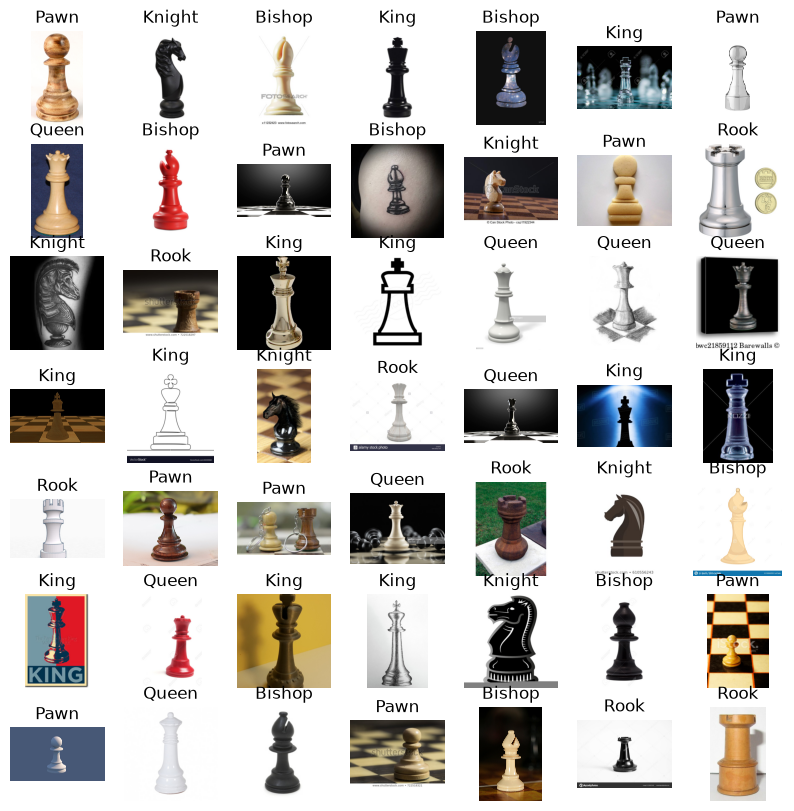

In [33]:
# Plot a grid of sample images from the dataset
import matplotlib.pyplot as plt

def plot_image_grid(dataset, num_images=9):
    plt.figure(figsize=(10, 10))
    grid_size = int(num_images ** 0.5)  # Calculate the grid size based on the number of images
    for i in range(num_images):
        plt.subplot(grid_size, grid_size, i + 1)
        plt.imshow(dataset[i]["image"])
        plt.title(dataset.features["label"].int2str(dataset[i]["label"]))
        #plt.title(dataset[i]["label"].int2str(dataset[i]["label"]))
        plt.axis("off")
    plt.show()

#plot_image_grid(dataset["train"])
plot_image_grid(dataset["validation"], 49)
#plot_image_grid(dataset["test"])

In [35]:

# --- Setup training arguments and Trainer ---

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    
    num_train_epochs=100,
    
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    
    weight_decay=0.01,
    
    #logging_dir=LOGGING_DIR,
    logging_strategy="epoch",
    learning_rate=1e-4, # 0.0001
    eval_strategy="epoch", # evaluate every epoch, alternative to "steps"
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,

    report_to="trackio",    # Report to TrackIO for experiment tracking
    run_name="vit-base-patch16-224-in21k-finetuned-chessman-2026-10-15-beft",
    #push_to_hub=True,    
    dataloader_pin_memory=False  # silence the warning on MacOS Apple Silicon
)

from transformers import EarlyStoppingCallback
early_stopping_callback = EarlyStoppingCallback(
    early_stopping_patience=3,  
    early_stopping_threshold=0.005
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=prepared_dataset["train"],
    eval_dataset=prepared_dataset["validation"],
    compute_metrics=compute_metrics,
    callbacks=[early_stopping_callback]
)

# --- Start training the model ---
trainer.train()

# --- Save the fine-tuned model ---
model.save_pretrained(OUTPUT_DIR)

* Resumed existing run: vit-base-patch16-224-in21k-finetuned-chessman-2026-10-15-beft


Epoch,Training Loss,Validation Loss,Accuracy
1,0.434547,0.582562,0.909091
2,0.408269,0.570353,0.909091
3,0.386248,0.552207,0.909091
4,0.367387,0.537675,0.909091


* Run finished. Uploading logs to Trackio (please wait...)


In [ ]:
import peft

In [39]:
predictions = trainer.predict(prepared_dataset["test"])
predictions.metrics


{'test_loss': 0.4054035544395447,
 'test_accuracy': 0.9464285714285714,
 'test_runtime': 1.6909,
 'test_samples_per_second': 33.119,
 'test_steps_per_second': 2.366}

In [40]:
import numpy as np
predicted_labels = np.argmax(predictions.predictions, axis=-1)
true_labels = predictions.label_ids
print(true_labels, predicted_labels, sep="\n")

[0 2 0 4 4 3 5 3 1 2 2 2 2 0 5 1 3 3 5 1 1 5 2 2 3 4 5 3 3 2 4 5 0 4 1 2 4
 0 1 5 2 3 3 4 5 2 3 3 4 4 5 5 2 3 3 1]
[0 2 0 4 4 3 5 3 1 2 2 2 2 0 5 1 3 3 5 1 1 5 2 2 3 4 5 3 3 2 4 5 3 4 1 2 4
 0 1 5 2 3 3 4 5 2 3 3 1 4 5 5 2 3 3 4]


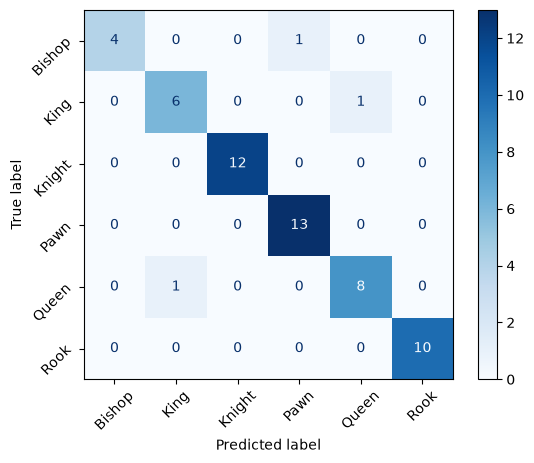

In [41]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

predictions = trainer.predict(prepared_dataset["test"])
y_pred = np.argmax(predictions.predictions, axis=1)
y_true = predictions.label_ids
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Blues)
disp.ax_.set_xticklabels(prepared_dataset["test"].features["label"].names, rotation=45)
disp.ax_.set_yticklabels(prepared_dataset["test"].features["label"].names, rotation=45)
plt.show()

Incorrectly classified sample indices: [32 48 55]
Predicted labels for incorrect samples: [3 1 4]
True labels for incorrect samples: [0 4 1]
Predicted label names for incorrect samples: ['Pawn', 'King', 'Queen']
True label names for incorrect samples: ['Bishop', 'Queen', 'King']
Incorrect samples: Dataset({
    features: ['image', 'label'],
    num_rows: 3
})


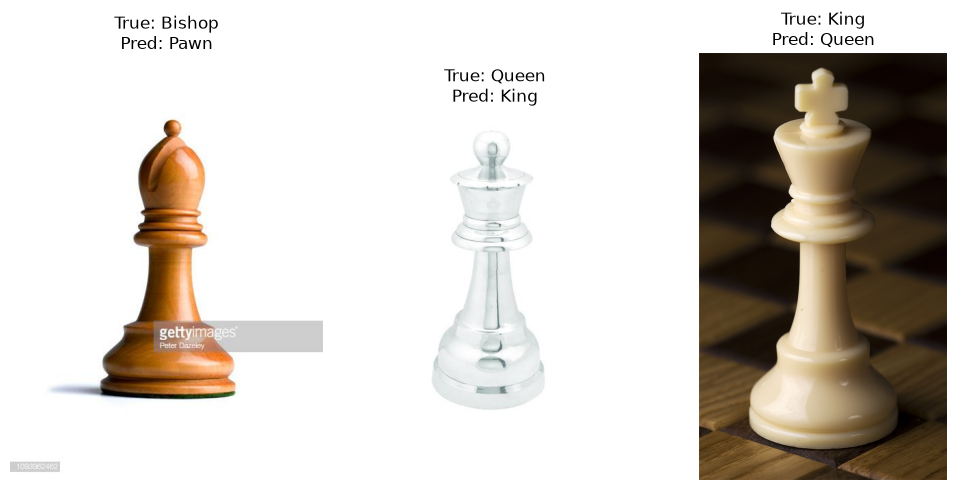

In [42]:
import matplotlib.pyplot as plt


incorrect_indices = np.where(true_labels != predicted_labels)[0]
incorrect_labels = predicted_labels[incorrect_indices]
true_labels_incorrect = true_labels[incorrect_indices]

true_label_names = dataset["test"].features["label"]

print("Incorrectly classified sample indices:", incorrect_indices)
print("Predicted labels for incorrect samples:", incorrect_labels)
print("True labels for incorrect samples:", true_labels_incorrect)

incorrect_label_names = dataset["test"].features["label"].int2str(incorrect_labels)
true_label_names_incorrect = dataset["test"].features["label"].int2str(true_labels_incorrect)
print("Predicted label names for incorrect samples:", incorrect_label_names)
print("True label names for incorrect samples:", true_label_names_incorrect)

incorrect_samples = dataset["test"].select(incorrect_indices)
print("Incorrect samples:", incorrect_samples)

num_plots = min(5, len(incorrect_samples))

plt.figure(figsize=(10, 5))
for i in range(num_plots):
    idx = incorrect_indices[i]
    # Assuming the dataset returns a dictionary with 'image' and 'label'
    sample = test_dataset[idx] 
    image = sample['image'] 
    
    plt.subplot(1, num_plots, i + 1)
    plt.imshow(image)
    plt.title(f"True: {true_label_names_incorrect[i]}\nPred: {incorrect_label_names[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

---

### Quantization

Quantization is a process that converts a model's floating-point numbers into lower-precision integers to reduce its size, speed up computation, and lower memory usage.

This makes it more efficient to deploy models, especially on devices with limited resources. By converting high-precision values to lower-precision ones, the model requires less memory, consumes less power, and runs faster.

**How it works**

 - **Lower precision:** Quantization takes the high-precision numbers (like 32-bit floating-point - float32) that make up a model's parameters and converts them into a smaller range of numbers, often using 8-bit integers (int8).  
 
 - **Mapping values:** The process maps the original range of floating-point values to a new, smaller range of integers. A scaling factor and zero-point are used to define this mapping.  

Quantization formula:

   x - floating point value

   S - Scaling factor

   Z - Zero-point (0 if floating-point range is negative to positive)

   q = round(x / S) + Z

   q -> final scaled integer representation of x

To retrieve the float-value (approximation):
  x_a = S * (q - Z)

Quantization error -> x - x_a



#### Example

In [44]:
import numpy as np
import torch
import matplotlib.pyplot as plt


# =============================================================================
# 1. MANUAL QUANTIZATION DEMONSTRATION
# =============================================================================

def manual_quantize_float32_to_uint8(fp_array, scale=None, zero_point=None):
    """
    Manual quantization from float32 to uint8
    Formula: quantized = round((fp_value / scale) + zero_point)
    """
    
    # Calculate quantization parameters if not provided
    if scale is None or zero_point is None:
        min_val = np.min(fp_array)
        max_val = np.max(fp_array)
        scale = (max_val - min_val) / 255.0  # uint8 range: 0-255
        zero_point = np.round(-min_val / scale)
    
    print(f"Quantization parameters:")
    print(f"  Scale: {scale:.6f}")
    print(f"  Zero point: {zero_point}")
    print(f"  Input range: [{min_val:.3f}, {max_val:.3f}]")
    print(f"  Quantized range: [0, 255]")
    
    # Quantization: float32 → uint8
    quantized = np.round((fp_array / scale) + zero_point)
    quantized = np.clip(quantized, 0, 255).astype(np.uint8)
    
    return quantized, scale, zero_point

def manual_dequantize_uint8_to_float32(quantized_array, scale, zero_point):
    """
    Dequantization from uint8 back to float32
    Formula: dequantized = (quantized - zero_point) * scale
    """
    dequantized = (quantized_array.astype(np.float32) - zero_point) * scale
    return dequantized




In [47]:
print("=== Quantization Demonstration: float32 → uint8 ===\n")

# Original float32 vector
#fp_vec = np.array([0.0, 0.1, 0.2, 0.3], dtype=np.float32)
fp_vec = np.array([-3.3345, -2.1234, 1.67, 3.14159, 5.334], dtype=np.float32)
print(f"Original float32 vector: {fp_vec}")
print(f"Data type: {fp_vec.dtype}")
print(f"Shape: {fp_vec.shape}\n")

print("1. MANUAL QUANTIZATION PROCESS")
print("=" * 50)
# Perform quantization
quantized_vec, scale, zero_point = manual_quantize_float32_to_uint8(fp_vec)

print(f"\nQuantization steps:")
print(f"  Original:    {fp_vec}")
print(f"  After scaling: {((fp_vec - zero_point) / scale).round(2)}")
print(f"  Quantized:    {quantized_vec}")
print(f"  Data type:    {quantized_vec.dtype}")
print(f"  Zero point:    {zero_point}")
print(f"  Scale:         {scale:.6f}")


=== Quantization Demonstration: float32 → uint8 ===

Original float32 vector: [-3.3345  -2.1234   1.67     3.14159  5.334  ]
Data type: float32
Shape: (5,)

1. MANUAL QUANTIZATION PROCESS
Quantization parameters:
  Scale: 0.033994
  Zero point: 98.0
  Input range: [-3.335, 5.334]
  Quantized range: [0, 255]

Quantization steps:
  Original:    [-3.3345  -2.1234   1.67     3.14159  5.334  ]
  After scaling: [-2980.94 -2945.32 -2833.73 -2790.44 -2725.94]
  Quantized:    [  0  36 147 190 255]
  Data type:    uint8
  Zero point:    98.0
  Scale:         0.033994


In [48]:

# Dequantize back to float32
dequantized_vec = manual_dequantize_uint8_to_float32(quantized_vec, scale, zero_point)

print(f"\nDequantization:")
print(f"  Quantized:    {quantized_vec}")
print(f"  After scaling: {(quantized_vec.astype(np.float32) * scale).round(4)}")
print(f"  After zero_point: {dequantized_vec}")
print(f"  Original float32 vector: {fp_vec}")
print(f"  Data type:    {dequantized_vec.dtype}")



Dequantization:
  Quantized:    [  0  36 147 190 255]
  After scaling: [0.     1.2238 4.9971 6.4589 8.6685]
  After zero_point: [-3.3314233 -2.1076353  1.6657116  3.1274586  5.337076 ]
  Original float32 vector: [-3.3345  -2.1234   1.67     3.14159  5.334  ]
  Data type:    float32


In [49]:

# Calculate quantization error
quantization_error = np.abs(fp_vec - dequantized_vec)
print(f"\nQuantization Error:")
print(f"  Original:    {fp_vec}")
print(f"  Dequantized: {dequantized_vec}")
print(f"  Error:       {quantization_error}")
print(f"  Mean Absolute Error: {np.mean(quantization_error):.6f}")
print(f"  Max Error: {np.max(quantization_error):.6f}")



Quantization Error:
  Original:    [-3.3345  -2.1234   1.67     3.14159  5.334  ]
  Dequantized: [-3.3314233 -2.1076353  1.6657116  3.1274586  5.337076 ]
  Error:       [0.00307679 0.01576471 0.00428832 0.01413155 0.00307608]
  Mean Absolute Error: 0.008067
  Max Error: 0.015765


In [19]:
from transformers import AutoModelForImageClassification, BitsAndBytesConfig

CHECKPOINT = "yzu1114621/resnet-50-openvino-8bit"

model_8bit = AutoModelForImageClassification.from_pretrained(
    CHECKPOINT,
    load_in_8bit=True,  # Enable 8-bit quantization
    device_map="auto",   # Automatically map model to available devices
)

config.json:   0%|          | 0.00/69.8k [00:00<?, ?B/s]

OSError: yzu1114621/resnet-50-openvino-8bit does not appear to have a file named pytorch_model.bin or model.safetensors.

In [ ]:

# =============================================================================
# 2. DIFFERENT QUANTIZATION SCHEMES
# =============================================================================

print("\n\n2. DIFFERENT QUANTIZATION SCHEMES")
print("=" * 50)

# Scheme 1: Symmetric Quantization (zero_point = 0)
def symmetric_quantize(fp_array):
    """Symmetric quantization around zero"""
    max_abs = np.max(np.abs(fp_array))
    scale = max_abs / 127.0  # int8 symmetric range: -127 to 127
    
    # For uint8, we shift to positive range
    scale_sym = (2 * max_abs) / 255.0
    zero_point_sym = 127
    
    quantized = np.round((fp_array + max_abs) / scale_sym)
    quantized = np.clip(quantized, 0, 255).astype(np.uint8)
    
    return quantized, scale_sym, zero_point_sym

# Scheme 2: Asymmetric Quantization (min-max, as shown above)
def asymmetric_quantize(fp_array):
    """Asymmetric quantization using min-max range"""
    return manual_quantize_float32_to_uint8(fp_array)

# Scheme 3: Fixed-point Quantization
def fixed_point_quantize(fp_array, fractional_bits=4):
    """Fixed-point quantization with specified fractional bits"""
    # Scale factor: 2^fractional_bits
    scale_factor = 2 ** fractional_bits
    quantized = np.round(fp_array * scale_factor)
    
    # Convert to appropriate integer type
    max_val = np.max(np.abs(quantized))
    if max_val <= 127:
        dtype = np.int8
        quantized = np.clip(quantized, -128, 127).astype(dtype)
    else:
        dtype = np.int16
        quantized = np.clip(quantized, -32768, 32767).astype(dtype)
    
    return quantized, scale_factor, dtype

print("Symmetric Quantization:")
quant_sym, scale_sym, zp_sym = symmetric_quantize(fp_vec)
dequant_sym = manual_dequantize_uint8_to_float32(quant_sym, scale_sym, zp_sym)
error_sym = np.abs(fp_vec - dequant_sym)
print(f"  Quantized: {quant_sym}")
print(f"  Dequantized: {dequant_sym}")
print(f"  Error: {error_sym}")

print("\nAsymmetric Quantization:")
quant_asym, scale_asym, zp_asym = asymmetric_quantize(fp_vec)
dequant_asym = manual_dequantize_uint8_to_float32(quant_asym, scale_asym, zp_asym)
error_asym = np.abs(fp_vec - dequant_asym)
print(f"  Quantized: {quant_asym}")
print(f"  Dequantized: {dequant_asym}")
print(f"  Error: {error_asym}")

print("\nFixed-point Quantization (4 fractional bits):")
quant_fp, scale_fp, dtype_fp = fixed_point_quantize(fp_vec, fractional_bits=4)
dequant_fp = quant_fp.astype(np.float32) / scale_fp
error_fp = np.abs(fp_vec - dequant_fp)
print(f"  Quantized: {quant_fp} (dtype: {dtype_fp})")
print(f"  Dequantized: {dequant_fp}")
print(f"  Error: {error_fp}")


In [20]:

# =============================================================================
# 3. PYTORCH QUANTIZATION API
# =============================================================================

print("\n\n3. PYTORCH QUANTIZATION API")
print("=" * 50)

# Convert to PyTorch tensor
fp_tensor = torch.tensor(fp_vec, dtype=torch.float32)
print(f"PyTorch tensor: {fp_tensor}")
print(f"Data type: {fp_tensor.dtype}")

# Method 1: Using torch.quantize_per_tensor (for int8)
# Note: PyTorch's quantize_per_tensor works with int8, not uint8 directly
quantized_tensor = torch.quantize_per_tensor(
    fp_tensor, 
    scale=scale, 
    zero_point=int(zero_point), 
    dtype=torch.quint8  # unsigned int8
)

print(f"\nPyTorch Quantized Tensor:")
print(f"  Values: {quantized_tensor.int_repr()}")  # Get integer values
print(f"  Scale: {quantized_tensor.q_scale()}")
print(f"  Zero point: {quantized_tensor.q_zero_point()}")
print(f"  Data type: {quantized_tensor.dtype}")

# Dequantize
dequantized_tensor = quantized_tensor.dequantize()
print(f"\nDequantized Tensor:")
print(f"  Values: {dequantized_tensor}")
print(f"  Error: {torch.abs(fp_tensor - dequantized_tensor)}")




3. PYTORCH QUANTIZATION API
PyTorch tensor: tensor([-4.3345, -2.1234,  1.6700,  3.1416,  5.0000])
Data type: torch.float32

PyTorch Quantized Tensor:
  Values: tensor([  0,  60, 164, 204, 255], dtype=torch.uint8)
  Scale: 0.03660587966442108
  Zero point: 118
  Data type: torch.quint8

Dequantized Tensor:
  Values: tensor([-4.3195, -2.1231,  1.6839,  3.1481,  5.0150])
  Error: tensor([0.0150, 0.0003, 0.0139, 0.0065, 0.0150])


/var/folders/8r/bd41h17j3g733j4twtb7rh9c0000gn/T/ipykernel_44976/3152051549.py:15: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/quantized/Quantizer.cpp:116.)
  quantized_tensor = torch.quantize_per_tensor(


In [21]:

# Method 2: Manual quantization in PyTorch
def pytorch_manual_quantize(tensor, num_bits=8):
    """Manual quantization in PyTorch"""
    min_val = tensor.min()
    max_val = tensor.max()
    
    scale = (max_val - min_val) / (2 ** num_bits - 1)
    zero_point = torch.round(-min_val / scale)
    
    # Quantize
    quantized = torch.round((tensor - zero_point) / scale)
    quantized = torch.clamp(quantized, 0, 255).to(torch.uint8)
    
    return quantized, scale, zero_point

quant_pt, scale_pt, zp_pt = pytorch_manual_quantize(fp_tensor)
dequant_pt = quant_pt.float() * scale_pt + zp_pt

print(f"\nPyTorch Manual Quantization:")
print(f"  Quantized: {quant_pt}")
print(f"  Dequantized: {dequant_pt}")
print(f"  Error: {torch.abs(fp_tensor - dequant_pt)}")



PyTorch Manual Quantization:
  Quantized: tensor([0, 0, 0, 0, 0], dtype=torch.uint8)
  Dequantized: tensor([118., 118., 118., 118., 118.])
  Error: tensor([122.3345, 120.1234, 116.3300, 114.8584, 113.0000])




4. QUANTIZATION EFFECTS VISUALIZATION
Quantization parameters:
  Scale: 0.007843
  Zero point: 128.0
  Input range: [-1.000, 1.000]
  Quantized range: [0, 255]


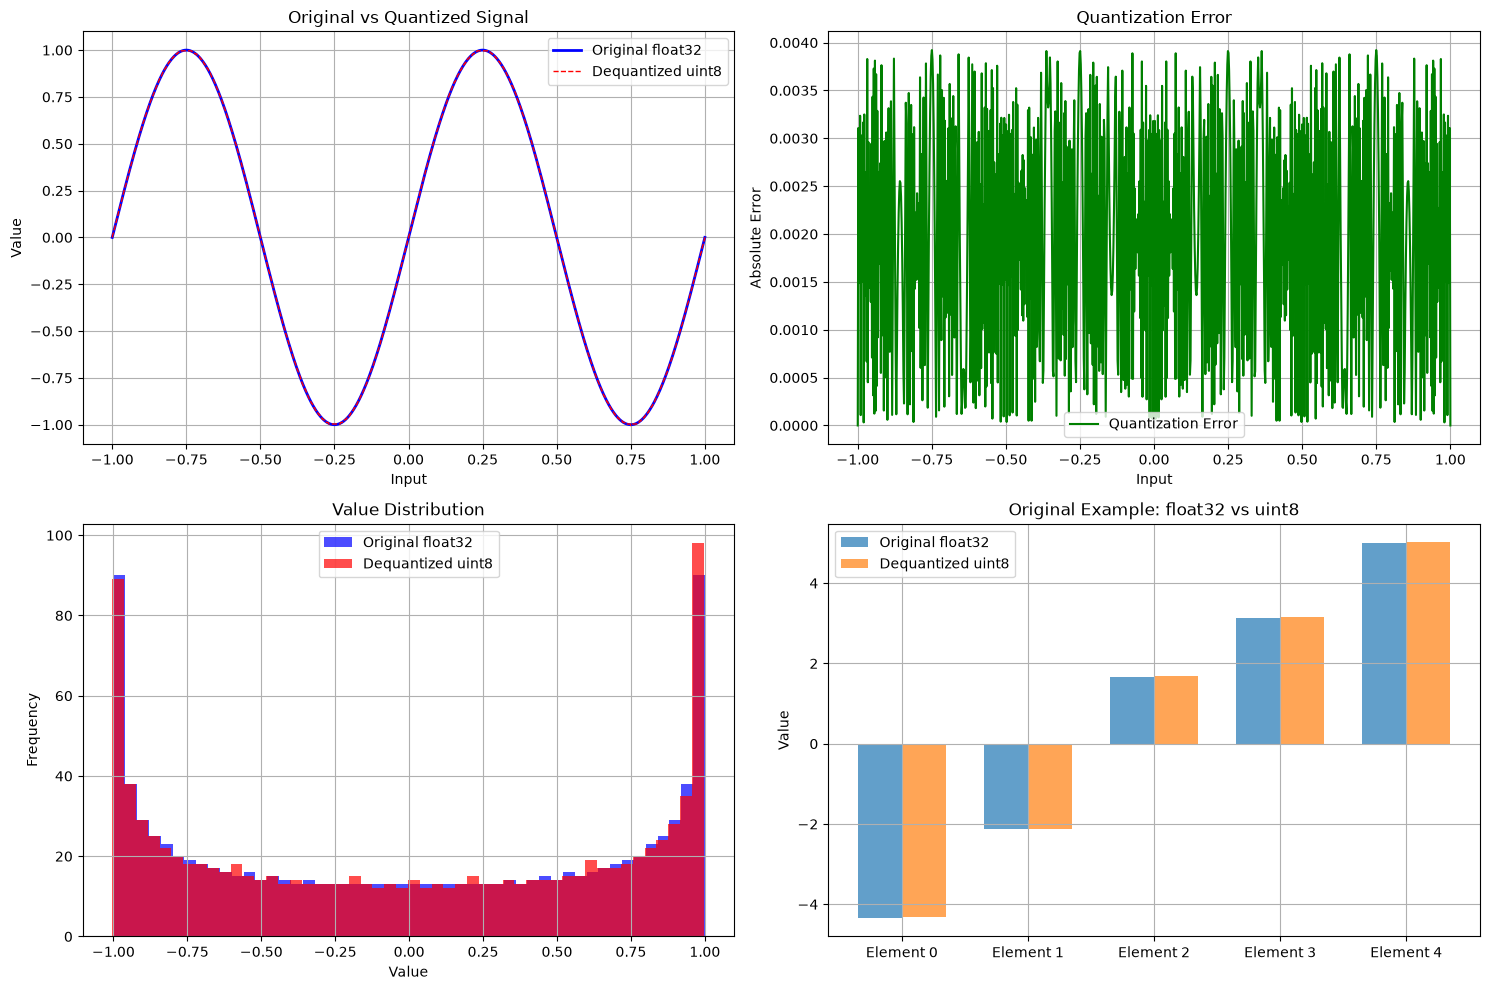

In [24]:

# =============================================================================
# 4. VISUALIZATION OF QUANTIZATION EFFECTS
# =============================================================================

print("\n\n4. QUANTIZATION EFFECTS VISUALIZATION")
print("=" * 50)

# Create a larger example to visualize
x_smooth = np.linspace(-1, 1, 1000, dtype=np.float32)
y_smooth = np.sin(x_smooth * 2 * np.pi)  # Sine wave

# Quantize the smooth curve
y_quantized, scale_large, zp_large = manual_quantize_float32_to_uint8(y_smooth)
y_dequantized = manual_dequantize_uint8_to_float32(y_quantized, scale_large, zp_large)

plt.figure(figsize=(15, 10))

# Plot 1: Original vs Quantized
plt.subplot(2, 2, 1)
plt.plot(x_smooth, y_smooth, 'b-', label='Original float32', linewidth=2)
plt.plot(x_smooth, y_dequantized, 'r--', label='Dequantized uint8', linewidth=1)
plt.title('Original vs Quantized Signal')
plt.xlabel('Input')
plt.ylabel('Value')
plt.legend()
plt.grid(True)

# Plot 2: Quantization Error
plt.subplot(2, 2, 2)
quant_error = np.abs(y_smooth - y_dequantized)
plt.plot(x_smooth, quant_error, 'g-', label='Quantization Error')
plt.title('Quantization Error')
plt.xlabel('Input')
plt.ylabel('Absolute Error')
plt.legend()
plt.grid(True)

# Plot 3: Histogram of values
plt.subplot(2, 2, 3)
plt.hist(y_smooth, bins=50, alpha=0.7, label='Original float32', color='blue')
plt.hist(y_dequantized, bins=50, alpha=0.7, label='Dequantized uint8', color='red')
plt.title('Value Distribution')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True)

# Plot 4: Our original example
plt.subplot(2, 2, 4)
x_pos = np.arange(len(fp_vec))
width = 0.35

plt.bar(x_pos - width/2, fp_vec, width, label='Original float32', alpha=0.7)
plt.bar(x_pos + width/2, dequantized_vec, width, label='Dequantized uint8', alpha=0.7)
plt.xticks(x_pos, [f'Element {i}' for i in range(len(fp_vec))])
plt.title('Original Example: float32 vs uint8')
plt.ylabel('Value')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [ ]:
!pip install bitsandbytes

In [ ]:
from transformers import AutoModelForImageClassification, AutoImageProcessor, BitsAndBytesConfig
import torch

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16
)

processor = AutoImageProcessor.from_pretrained(CHECKPOINT)
model = AutoModelForImageClassification.from_pretrained(CHECKPOINT, 
    num_labels=num_classes,
    quantization_config=bnb_config
)

More details on the theory: https://huggingface.co/docs/optimum/en/concept_guides/quantization

---

In [29]:
from transformers import AutoModelForImageClassification
from peft import PeftModel

CHECKPOINT = "google/vit-base-patch16-224"
CHESSMAN_ADAPTER = "../../data/models/vit-peft-chessman"
num_classes = 6

base_model = AutoModelForImageClassification.from_pretrained(CHECKPOINT)


model = PeftModel.from_pretrained(base_model, CHESSMAN_ADAPTER, device_map="auto")
model

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

ValueError: No modules were targeted for adaptation. This might be caused by a combination of mismatched target modules and excluded modules. Please check your `target_modules` and `exclude_modules` configuration. You may also have only targeted modules that are marked to be saved (`modules_to_save`).

---